# **TCGA-STAD: tumor vs. normal differential expression and pathway enrichment**

**Purpose.** Demonstrate a DEG, GSEA and GO/KEGG workflow comparable to the radiogenomics analysis in Figure 7 of Jiang et al., Cell Reports Medicine 2023.

**Comparison used.** Figure 7 correlates gene expression with the deep learning radiomics score (DLRS), which requires running the HR-Rad-Net model on matched CT images. That isn't feasible here, so this notebook uses primary tumor vs. solid tissue normal as a stand-in to show the same analytical steps.

**Data.** TCGA-STAD RNA-seq (STAR gene counts) from GDC via TCGAbiolinks. All 36 solid tissue normals plus a random 60 of 412 primary tumors (seed 42).

**Running it.** Colab with the R runtime. On a fresh runtime the install cell takes about 35 minutes. Outputs go to figures/ and are bundled into results.zip at the end. Colab deletes files when the runtime resets, so download the zip before closing.

**Methods references.** DESeq2 (Love et al., Genome Biology 2014); apeglm (Zhu et al., Bioinformatics 2018); clusterProfiler (Wu et al., The Innovation 2021); GSEA (Subramanian et al., PNAS 2005); TCGAbiolinks (Colaprico et al., Nucleic Acids Research 2016).

## **1. Set up**

In [1]:
# Install once per runtime. On a fresh Colab R runtime this cell takes ~35 min.
# update = FALSE so already-installed packages aren't upgraded mid-session.
if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")

BiocManager::install(c("TCGAbiolinks", "SummarizedExperiment", "DESeq2",
                       "clusterProfiler", "org.Hs.eg.db", "enrichplot", "apeglm"),
                     ask = FALSE, update = FALSE)

install.packages(c("ggplot2", "ggrepel", "dplyr", "tibble"))

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'BiocVersion', 'TCGAbiolinks', 'SummarizedExperiment',
  'DESeq2', 'clusterProfiler', 'org.Hs.eg.db', 'enrichplot', 'apeglm'

also installing the dependencies ‘fontBitstreamVera’, ‘fontLiberation’, ‘formatR’, ‘fontquiver’, ‘filelock’, ‘XVector’, ‘lambda.r’, ‘futile.options’, ‘png’, ‘Biostrings’, ‘gridGraphics’, ‘gdtools’, ‘lazyeval’, ‘tweenr’, ‘polyclip’, ‘numDeriv’, ‘bdsmatrix’, ‘mvtnorm’, ‘BiocFileCache’, ‘R.oo’, ‘R.methodsS3’, ‘abind’, ‘SparseArray’, ‘futile.logger’, ‘snow’, ‘BH’, ‘RSQLite’, ‘KEGGREST’, ‘ggplotify’, ‘patchwork’, ‘ape’, ‘ggiraph’, ‘tidytree’, ‘treeio’, ‘ggforce’, ‘coda’, ‘bbmle’, ‘downloader’, ‘biomaRt’, 

In [2]:
suppressPackageStartupMessages({
  library(TCGAbiolinks); library(SummarizedExperiment); library(DESeq2)
  library(clusterProfiler); library(org.Hs.eg.db); library(enrichplot)
  library(ggplot2); library(ggrepel); library(dplyr); library(tibble)
})

dir.create("figures", showWarnings = FALSE)   # all plots and tables are written here

# Colab's default plotting font is monospace; using a sans-serif theme for all ggplots.
theme_lab <- function(size = 12) theme_minimal(base_size = size, base_family = "sans")
font_fix  <- theme(text = element_text(family = "sans"))   # for enrichplot dotplots

# Save plots through base R's png() device. In this Colab setup ggsave() wrote
# monospace text even with a sans theme, while png() rendered fonts correctly.
save_plot <- function(p, file, width, height, dpi = 300) {
  png(file, width = width, height = height, units = "in", res = dpi)
  print(p)
  invisible(dev.off())
}

## **2. Sample selection**

In [3]:
# Pulling GDC metadata for STAD RNA-seq (STAR gene counts).
# Restricting to primary tumor and solid tissue normal drops metastatic and recurrent samples.
query_all <- GDCquery(
  project = "TCGA-STAD",
  data.category = "Transcriptome Profiling",
  data.type = "Gene Expression Quantification",
  workflow.type = "STAR - Counts",
  sample.type = c("Primary Tumor", "Solid Tissue Normal")
)

meta <- getResults(query_all)
table(meta$sample_type)   # 412 tumors, 36 normals at the time of this run

# Normals are the limiting group, so keep all of them.
normals <- meta$cases[meta$sample_type == "Solid Tissue Normal"]
tumors  <- meta$cases[meta$sample_type == "Primary Tumor"]

# Fixed seed so the same tumors are selected on every rerun.
set.seed(42)

# A random 60 tumors keeps download and DESeq2 runtime manageable on Colab.
tumors_sub <- sample(tumors, min(60, length(tumors)))

length(normals); length(tumors_sub)   # 36 normal and 60 tumors

--------------------------------------

o GDCquery: Searching in GDC database

--------------------------------------

Genome of reference: hg38

--------------------------------------------

oo Accessing GDC. This might take a while...

--------------------------------------------

ooo Project: TCGA-STAD

--------------------

oo Filtering results

--------------------

ooo By data.type

ooo By workflow.type

ooo By sample.type

----------------

oo Checking data

----------------

ooo Checking if there are duplicated cases

ooo Checking if there are results for the query

-------------------

o Preparing output

-------------------




      Primary Tumor Solid Tissue Normal 
                412                  36 

[1] 36

[1] 60

## **3. Download and assemble counts**

In [4]:
# Re-query with only the selected barcodes, download (~400 MB) and build a
# SummarizedExperiment: genes x samples, with clinical annotation in colData.

query <- GDCquery(
  project = "TCGA-STAD",
  data.category = "Transcriptome Profiling",
  data.type = "Gene Expression Quantification",
  workflow.type = "STAR - Counts",
  barcode = c(normals, tumors_sub)
)

GDCdownload(query, files.per.chunk = 20)
stad <- GDCprepare(query)

# Sanity check: ~60,660 genes x 96 samples (36 normal, 60 tumor)
dim(stad)
table(stad$sample_type)

# Avoids re-downloading within the same runtime
saveRDS(stad, "stad_subset.rds")

--------------------------------------

o GDCquery: Searching in GDC database

--------------------------------------

Genome of reference: hg38

--------------------------------------------

oo Accessing GDC. This might take a while...

--------------------------------------------

ooo Project: TCGA-STAD

--------------------

oo Filtering results

--------------------

ooo By data.type

ooo By workflow.type

ooo By barcode

----------------

oo Checking data

----------------

ooo Checking if there are duplicated cases

ooo Checking if there are results for the query

-------------------

o Preparing output

-------------------


GDCdownload will download 96 files. A total of 407.628576 MB




Downloading: 21 MB     

Downloading: 21 MB     

Downloading: 22 MB     

Downloading: 22 MB     

|====================================================|100%                      Completed after 9 s 


Starting to add information to samples

 => Add clinical information to samples

 => Adding TCGA molecular information from marker papers

 => Information will have prefix 'paper_' 

stad subtype information from:doi:10.1038/nature13480

Available assays in SummarizedExperiment : 
  => unstranded
  => stranded_first
  => stranded_second
  => tpm_unstrand
  => fpkm_unstrand
  => fpkm_uq_unstrand



[1] 60660    96


      Primary Tumor Solid Tissue Normal 
                 60                  36 

In [5]:
# DESeq2 models raw integer counts and does its own library-size normalization,
# so using the "unstranded" count assay rather than TPM or FPKM.
counts <- assay(stad, "unstranded")

# The colData from TCGAbiolinks includes list columns that DESeq2 can't handle,
# so building a minimal sample table with just the comparison variable.
# Normal is the reference level: a positive log2FC means higher in tumor.
coldata <- data.frame(
  condition = factor(ifelse(stad$sample_type == "Solid Tissue Normal", "Normal", "Tumor"),
                     levels = c("Normal", "Tumor")),
  row.names = colnames(counts)
)

table(coldata$condition)   # Normal 36, Tumor 60


Normal  Tumor 
    36     60 

## **4. Differential expression (DESeq2)**

In [6]:
dds <- DESeqDataSetFromMatrix(countData = counts, colData = coldata, design = ~ condition)

# Keeping genes with >= 10 reads in at least 10 samples. Near-silent genes add
# multiple-testing burden without contributing information.
dds <- dds[rowSums(counts(dds) >= 10) >= 10, ]
dds <- DESeq(dds)

# Two versions of the result are kept on purpose:
#   res     - unshrunken; carries the Wald statistic used to rank genes for GSEA
#   res_shr - apeglm-shrunken fold changes, which stabilize noisy estimates for
#             low-count genes; used for DEG thresholds and the volcano plot
res     <- results(dds, contrast = c("condition", "Tumor", "Normal"))
res_shr <- lfcShrink(dds, coef = "condition_Tumor_vs_Normal", type = "apeglm")

# Strip the Ensembl version suffix (ENSG00000141510.18 -> ENSG00000141510) so IDs
# match org.Hs.eg.db, then add symbols (plot labels) and Entrez IDs (GO/KEGG).
# Where one Ensembl ID maps to several symbols, the first is kept.
res_df <- as.data.frame(res) %>%
  rownames_to_column("ensembl_id") %>%
  mutate(ensembl_clean = sub("\\..*", "", ensembl_id),
         lfc_shrunk = res_shr$log2FoldChange)

res_df$symbol <- mapIds(org.Hs.eg.db, keys = res_df$ensembl_clean, column = "SYMBOL",
                        keytype = "ENSEMBL", multiVals = "first")
res_df$entrez <- mapIds(org.Hs.eg.db, keys = res_df$ensembl_clean, column = "ENTREZID",
                        keytype = "ENSEMBL", multiVals = "first")

# summary() reports DESeq2's default cutoff (padj < 0.1).
# The DEG count below uses padj < 0.05 and |shrunken log2FC| > 1.
summary(res)
sum(res_df$padj < 0.05 & abs(res_df$lfc_shrunk) > 1, na.rm = TRUE)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 1677 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895

'select()' returned 1:many mapping between keys and columns

'select()' returned 1:many mapping between keys and columns




out of 31110 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 11160, 36%
LFC < 0 (down)     : 7413, 24%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 2)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



[1] 6855

In [7]:
# Checkpoint
saveRDS(dds, "dds.rds")
saveRDS(res_df, "res_df.rds")

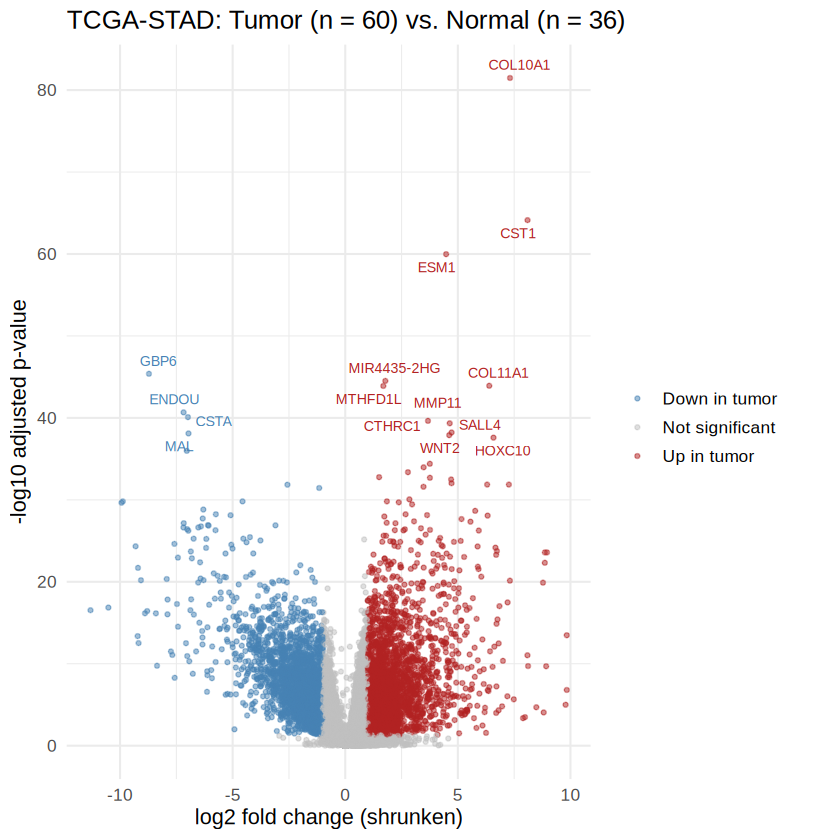

In [8]:
# Volcano plot, using the same DEG thresholds as above.
# The 15 most significant DEGs with a gene symbol are labeled.
res_df$status <- "Not significant"
res_df$status[res_df$lfc_shrunk >  1 & res_df$padj < 0.05] <- "Up in tumor"
res_df$status[res_df$lfc_shrunk < -1 & res_df$padj < 0.05] <- "Down in tumor"

top_lab <- res_df %>% filter(status != "Not significant", !is.na(symbol)) %>% slice_min(padj, n = 15)

n_t <- sum(coldata$condition == "Tumor"); n_n <- sum(coldata$condition == "Normal")

p_volcano <- ggplot(res_df, aes(lfc_shrunk, -log10(padj), color = status)) +
  geom_point(alpha = 0.5, size = 1) +
  geom_text_repel(data = top_lab, aes(label = symbol), size = 3, max.overlaps = 20,
                  show.legend = FALSE, family = "sans") +
  scale_color_manual(values = c("Up in tumor" = "firebrick", "Down in tumor" = "steelblue",
                                "Not significant" = "grey75")) +
  theme_lab(13) +
  labs(title = sprintf("TCGA-STAD: Tumor (n = %d) vs. Normal (n = %d)", n_t, n_n),
       x = "log2 fold change (shrunken)", y = "-log10 adjusted p-value", color = "")

p_volcano
save_plot(p_volcano, "figures/01_volcano.png", 8, 6)

## **5. Quality checks**

using ntop=500 top features by variance



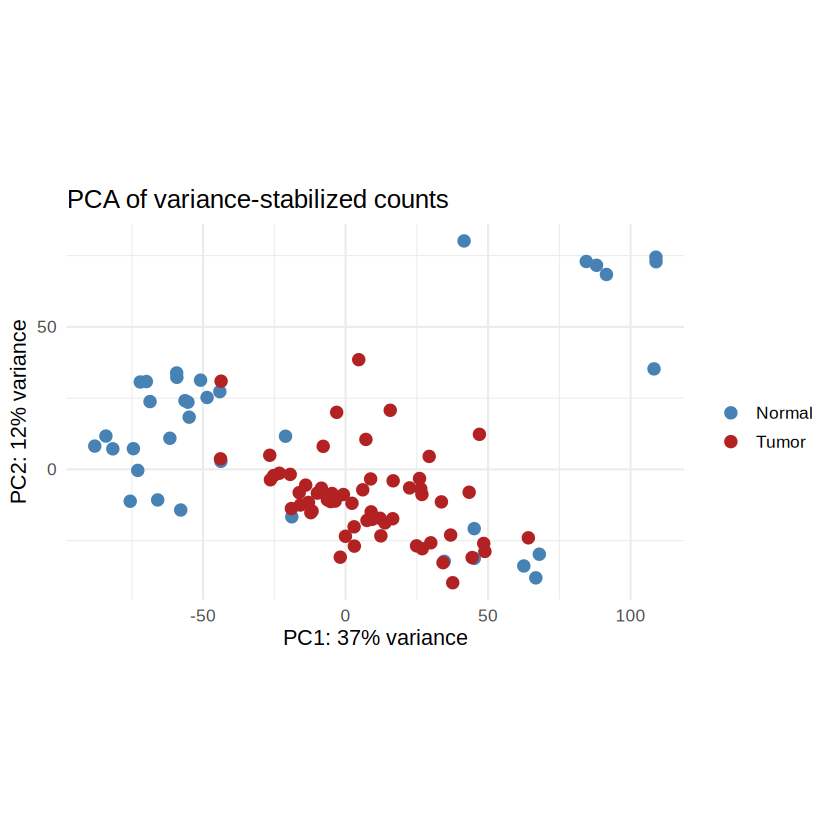

In [9]:
# Checks that the DEG results are trustworthy before interpreting pathways.
# What to look for:
#   PCA          - tumor and normal form separate clusters; note any outliers
#   p-value hist - flat floor with a spike near 0; a U-shape or mid hump means trouble
#   MA plot      - most genes near 0; shrinkage pulls noisy low-count genes toward 0
#   dispersion   - gene estimates scatter around the fitted trend and shrink toward it
#   controls     - genes with a known expected direction agree with the results

# PCA on variance-stabilized counts. blind = TRUE so the transform ignores the design,
# which gives an unbiased QC view.
vsd <- vst(dds, blind = TRUE)
p_pca <- plotPCA(vsd, intgroup = "condition") +
  scale_color_manual(values = c("Normal" = "steelblue", "Tumor" = "firebrick")) +
  theme_lab(13) + labs(title = "PCA of variance-stabilized counts", color = "")
p_pca
save_plot(p_pca, "figures/09_pca.png", 7, 6)

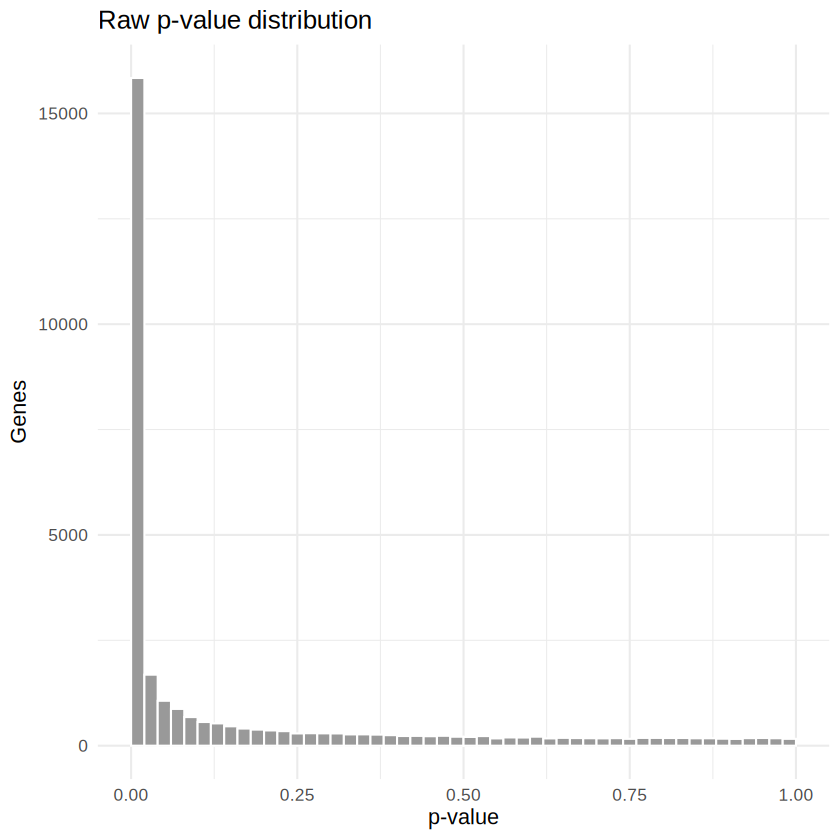

agg_record_cf5781f47be 
                     2

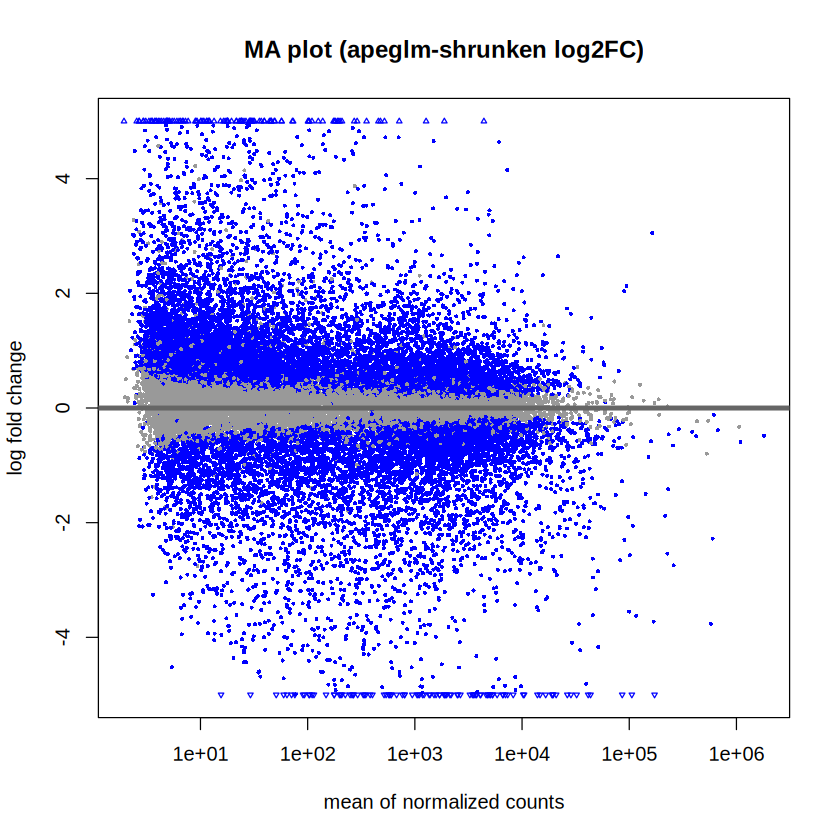

agg_record_cf5781f47be 
                     2

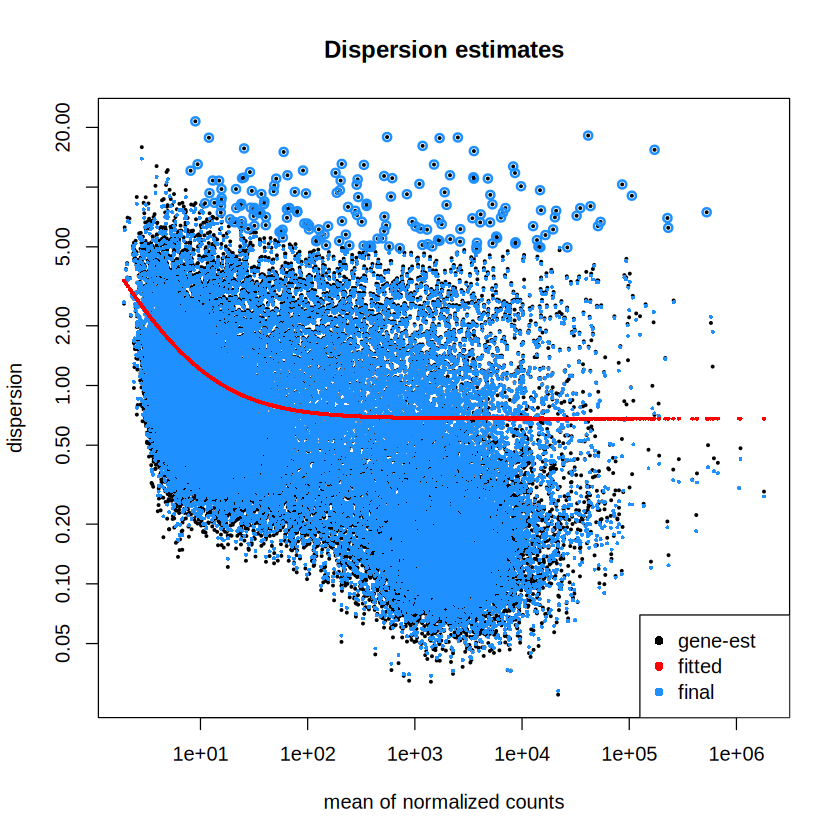

In [10]:
# Raw p-value distribution across all tested genes.
p_hist <- ggplot(res_df %>% filter(!is.na(pvalue)), aes(pvalue)) +
  geom_histogram(breaks = seq(0, 1, 0.02), fill = "grey60", color = "white") +
  theme_lab(13) + labs(title = "Raw p-value distribution", x = "p-value", y = "Genes")
p_hist
save_plot(p_hist, "figures/10_pvalue_histogram.png", 7, 5)

# MA plot (shrunken fold changes) and dispersion estimates. These are base-R plots,
# so each is drawn once on screen and once to file.
plotMA(res_shr, ylim = c(-5, 5), main = "MA plot (apeglm-shrunken log2FC)")
png("figures/11_ma_plot.png", width = 1600, height = 1200, res = 200)
plotMA(res_shr, ylim = c(-5, 5), main = "MA plot (apeglm-shrunken log2FC)")
dev.off()

plotDispEsts(dds, main = "Dispersion estimates")
png("figures/12_dispersion.png", width = 1600, height = 1200, res = 200)
plotDispEsts(dds, main = "Dispersion estimates")
dev.off()

symbol,expected,lfc_shrunk,padj,observed,agrees
<chr>,<chr>,<dbl>,<dbl>,<chr>,<lgl>
MKI67,Up,1.8396588,3.251328e-12,Up,TRUE
TOP2A,Up,2.5340987,1.581280e-19,Up,TRUE
GKN1,Down,-2.5401438,7.361959e-04,Down,TRUE
GKN2,Down,-2.8462553,1.211002e-04,Down,TRUE
ATP4A,Down,-2.3463693,7.010640e-16,Down,TRUE
ATP4B,Down,-2.7900778,4.467964e-04,Down,TRUE
PGC,Down,-0.7958997,1.137998e-01,Down,TRUE


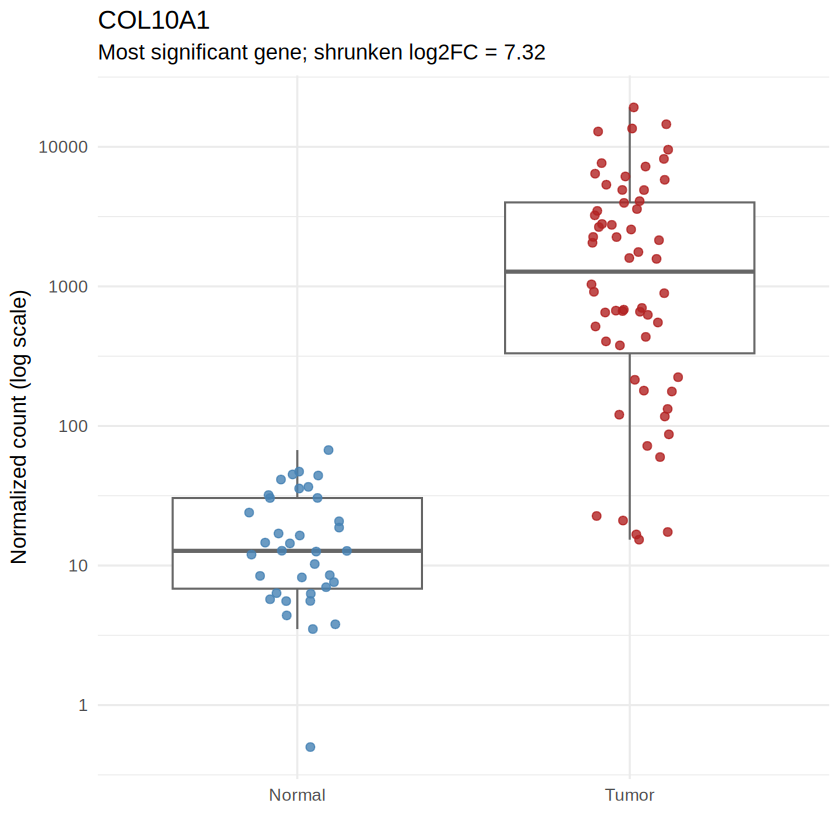

In [11]:
# Positive controls: genes whose direction is expected before looking at the data.
#   MKI67, TOP2A             - proliferation markers, expected up in tumor
#   GKN1, GKN2, ATP4A,
#   ATP4B, PGC               - normal gastric mucosa genes (gastrokines, parietal and
#                              chief cell genes), expected down in tumor
# A control that disagrees is a reason to check the contrast direction or sample labels.
controls <- tibble(
  symbol   = c("MKI67", "TOP2A", "GKN1", "GKN2", "ATP4A", "ATP4B", "PGC"),
  expected = c("Up", "Up", "Down", "Down", "Down", "Down", "Down")
)

pos_ctrl <- controls %>%
  left_join(res_df %>% dplyr::select(symbol, lfc_shrunk, padj), by = "symbol") %>%
  mutate(observed = ifelse(lfc_shrunk > 0, "Up", "Down"),
         agrees   = observed == expected)
pos_ctrl

# Direction check on the single most significant gene: its normalized counts should
# visibly match the sign of its fold change.
top_gene <- res_df %>% filter(!is.na(padj)) %>% slice_min(padj, n = 1, with_ties = FALSE)
top_name <- ifelse(is.na(top_gene$symbol), top_gene$ensembl_id, top_gene$symbol)

tg <- plotCounts(dds, gene = top_gene$ensembl_id, intgroup = "condition", returnData = TRUE)
p_tg <- ggplot(tg, aes(condition, count, color = condition)) +
  geom_boxplot(outlier.shape = NA, color = "grey40") +
  geom_jitter(width = 0.15, size = 2, alpha = 0.8) +
  scale_y_log10() +
  scale_color_manual(values = c("Normal" = "steelblue", "Tumor" = "firebrick")) +
  theme_lab(13) + theme(legend.position = "none") +
  labs(title = top_name, subtitle = sprintf("Most significant gene; shrunken log2FC = %.2f", top_gene$lfc_shrunk),
       x = "", y = "Normalized count (log scale)")
p_tg
save_plot(p_tg, "figures/13_top_gene_counts.png", 6, 5)

## **6. Gene set enrichment analysis (GSEA)**

In [12]:
# GSEA uses every tested gene, ranked, with no significance cutoff.
# Rank by the Wald statistic, which captures both direction and strength of evidence.
# Several Ensembl IDs can map to one Entrez ID; keep the one with the largest |stat|.
gl_df <- res_df %>%
  filter(!is.na(entrez), !is.na(stat)) %>%
  group_by(entrez) %>% slice_max(abs(stat), n = 1, with_ties = FALSE) %>% ungroup()

ranked <- sort(setNames(gl_df$stat, gl_df$entrez), decreasing = TRUE)
length(ranked)

[1] 22658

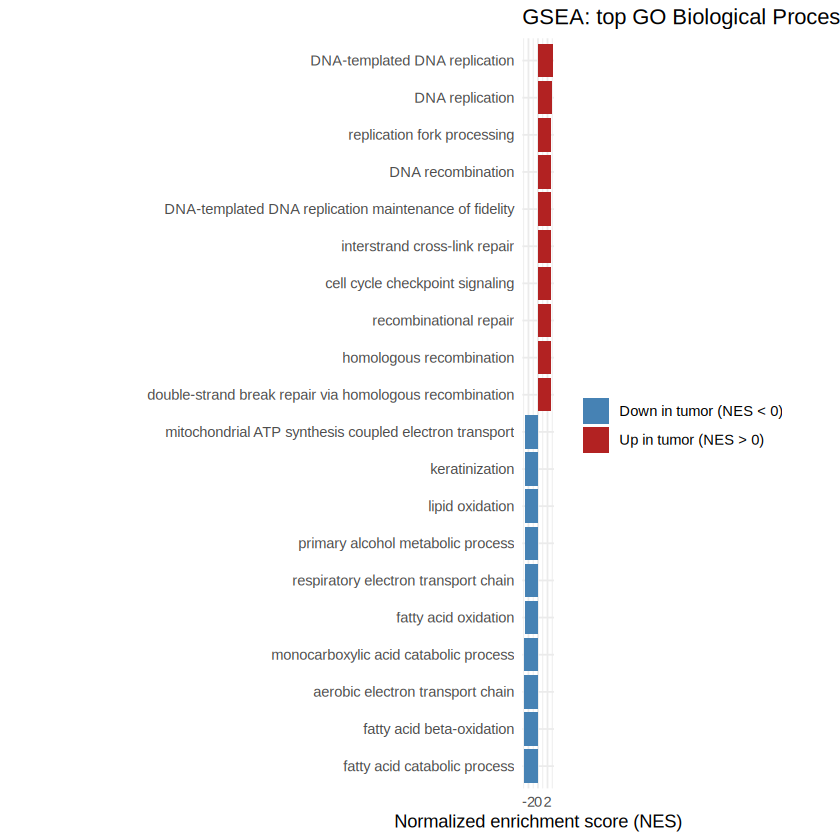

In [13]:
# Pre-ranked GSEA against GO Biological Process.
# Size limits (15-500 genes) drop very narrow and very broad terms.
# eps = 0 returns exact small p-values instead of a lower bound.
gsea_go <- gseGO(geneList = ranked, OrgDb = org.Hs.eg.db, ont = "BP", keyType = "ENTREZID",
                 minGSSize = 15, maxGSSize = 500, pvalueCutoff = 0.05, eps = 0, verbose = FALSE)

# Top 10 terms at each end. Positive NES = enriched among genes higher in tumor.
go_df  <- as.data.frame(gsea_go) %>% arrange(desc(NES))
go_top <- bind_rows(head(go_df, 10), tail(go_df, 10))

p_go <- ggplot(go_top, aes(reorder(Description, NES), NES, fill = NES > 0)) +
  geom_col() + coord_flip() +
  scale_fill_manual(values = c("TRUE" = "firebrick", "FALSE" = "steelblue"),
                    labels = c("TRUE" = "Up in tumor (NES > 0)", "FALSE" = "Down in tumor (NES < 0)"), name = "") +
  theme_lab(11) +
  labs(title = "GSEA: top GO Biological Process terms", x = "", y = "Normalized enrichment score (NES)")

p_go
save_plot(p_go, "figures/02_gsea_go_NES.png", 9, 7)

Reading KEGG annotation online: "https://rest.kegg.jp/link/hsa/pathway"...

Reading KEGG annotation online: "https://rest.kegg.jp/list/pathway/hsa"...



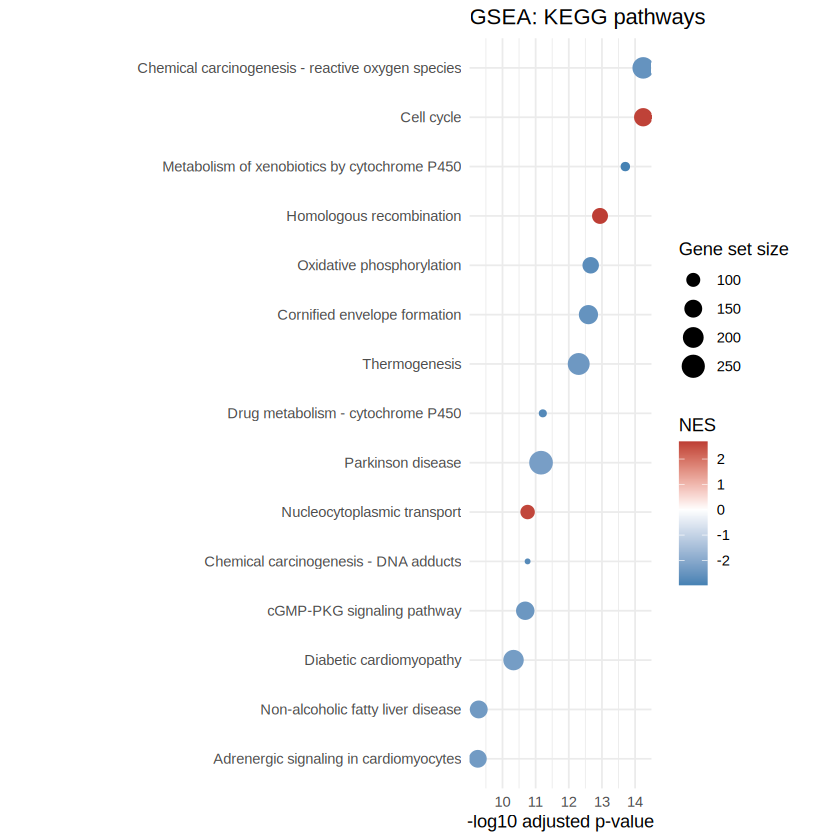

In [14]:
# Same ranked list against KEGG pathways. Needs internet access (KEGG REST API).
# A message that kegg_category.rda is being downloaded online is expected.
# Note: disease-named pathways (e.g. Parkinson disease, Thermogenesis, NAFLD) share many
# mitochondrial respiratory-chain genes with oxidative phosphorylation. Read them as part
# of the mitochondrial signal, not as evidence about those diseases.
gsea_kegg <- gseKEGG(geneList = ranked, organism = "hsa", minGSSize = 10, maxGSSize = 500,
                     pvalueCutoff = 0.05, eps = 0, verbose = FALSE)

kegg_df  <- as.data.frame(gsea_kegg) %>% arrange(p.adjust)
kegg_top <- head(kegg_df, 15)

p_kegg <- ggplot(kegg_top, aes(reorder(Description, -p.adjust), -log10(p.adjust),
                               size = setSize, color = NES)) +
  geom_point() + coord_flip() +
  scale_color_gradient2(low = "steelblue", mid = "white", high = "firebrick", midpoint = 0) +
  theme_lab(11) +
  labs(title = "GSEA: KEGG pathways", x = "", y = "-log10 adjusted p-value",
       size = "Gene set size", color = "NES")

p_kegg
save_plot(p_kegg, "figures/03_gsea_kegg_bubble.png", 9, 6)

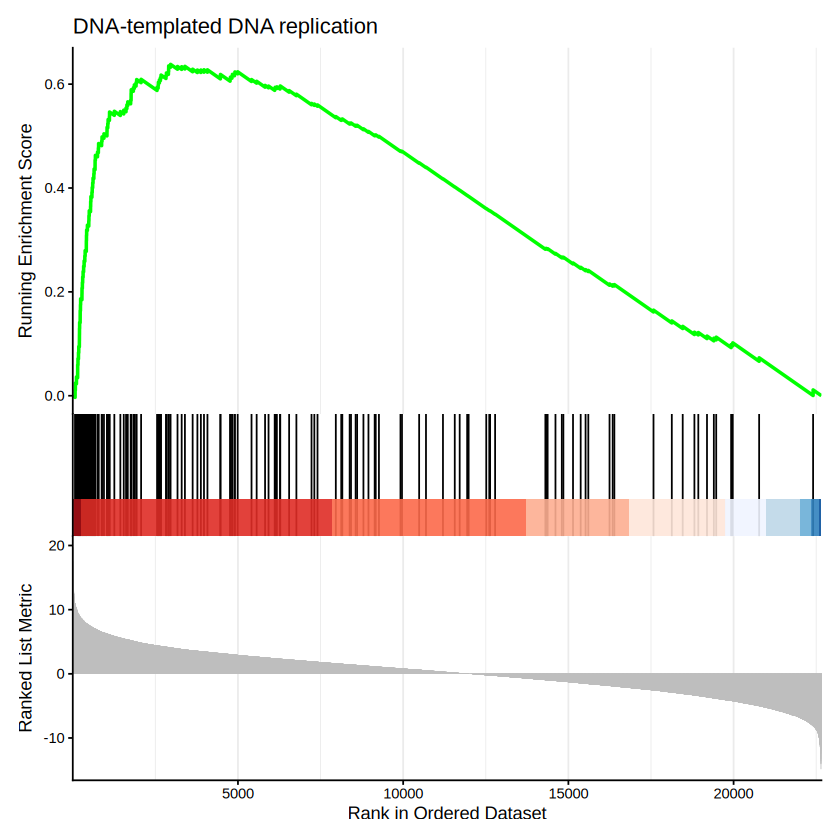

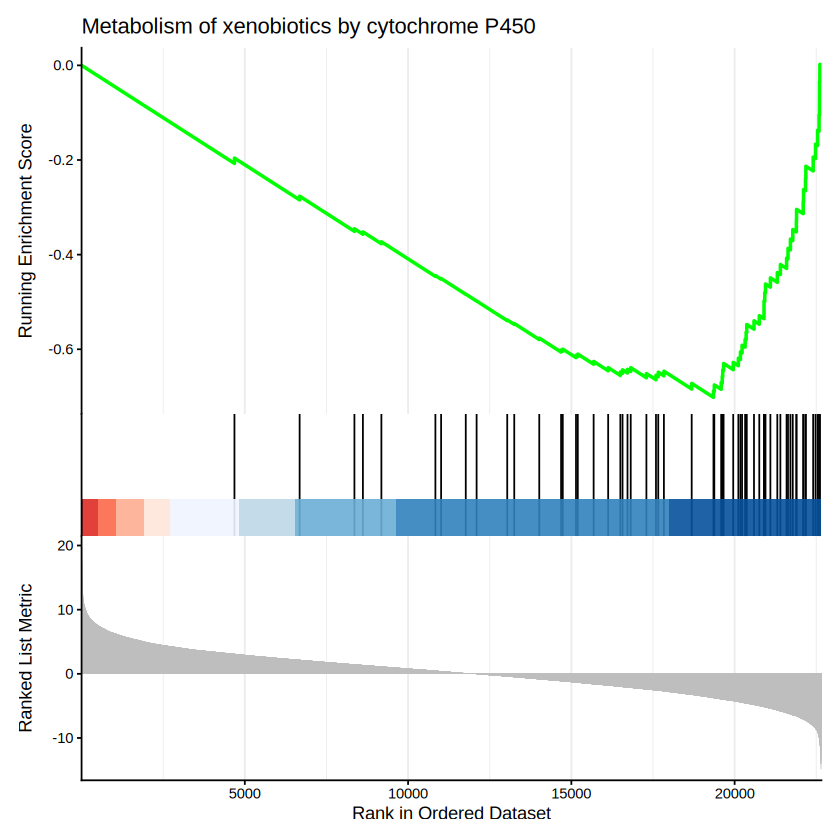

In [15]:
# Running enrichment-score plots for the top GO term and top KEGG pathway.
p_e1 <- gseaplot2(gsea_go,   geneSetID = 1, title = gsea_go$Description[1])
p_e2 <- gseaplot2(gsea_kegg, geneSetID = 1, title = gsea_kegg$Description[1])
p_e1; p_e2

save_plot(p_e1, "figures/04_enrichment_top_GO.png", 8, 6)
save_plot(p_e2, "figures/05_enrichment_top_KEGG.png", 8, 6)

In [16]:
# Leading-edge check: the genes driving the top terms should make biological sense
# (e.g. MCM-family genes for DNA replication). setReadable converts Entrez IDs to symbols.
go_read <- as.data.frame(setReadable(gsea_go, OrgDb = org.Hs.eg.db, keyType = "ENTREZID")) %>%
  arrange(desc(NES))
leading_edge <- function(i) head(strsplit(go_read$core_enrichment[i], "/")[[1]], 15)

cat("Highest NES (higher in tumor):", go_read$Description[1], "\n")
print(leading_edge(1))
cat("\nLowest NES (higher in normal):", go_read$Description[nrow(go_read)], "\n")
print(leading_edge(nrow(go_read)))

Highest NES (higher in tumor): DNA-templated DNA replication 
 [1] "RFC3"     "EME1"     "DNA2"     "MMS22L"   "CDC7"     "PRIM2"   
 [7] "ATAD5"    "DBF4"     "BRCA1"    "DTL"      "EXO1"     "FAM111A" 
[13] "TIMELESS" "RFC4"     "MCM10"   

Lowest NES (higher in normal): fatty acid catabolic process 
 [1] "ABCD2" "AKT1"  "AKT2"  "LPIN1" "LONP2" "ETFA"  "ACOXL" "ECHS1" "ECI2" 
[10] "AIG1"  "PPARD" "PPARA" "ABCD4" "HACL1" "ACOX1"


## **7. Over-representation analysis (GO / KEGG), split by direction**

[1] 2465

[1] 2458

kegg_category.rda is not found, download it online...



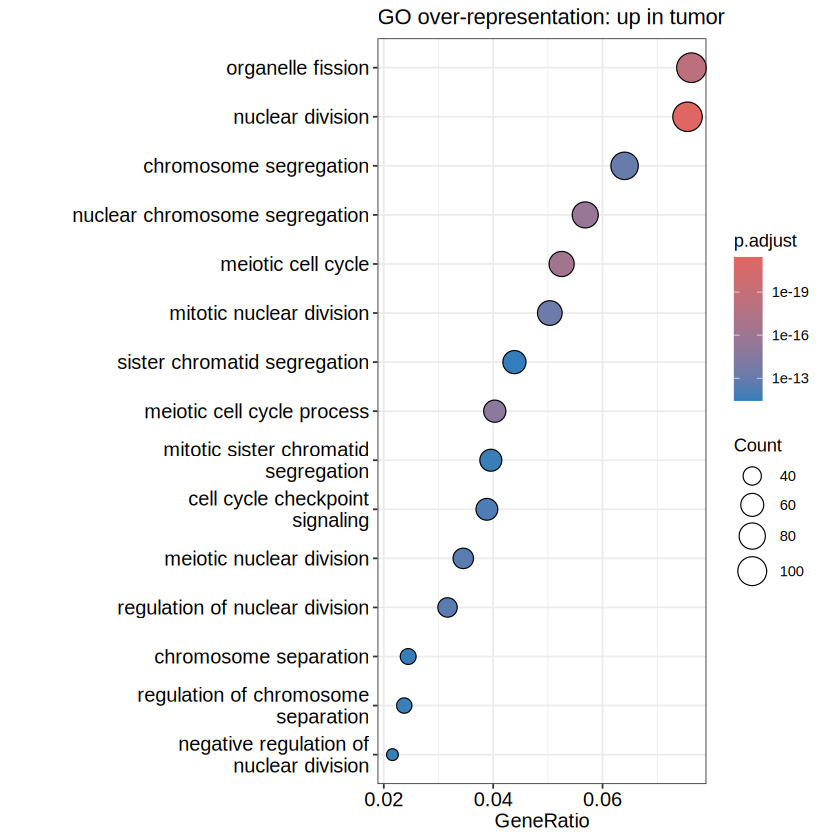

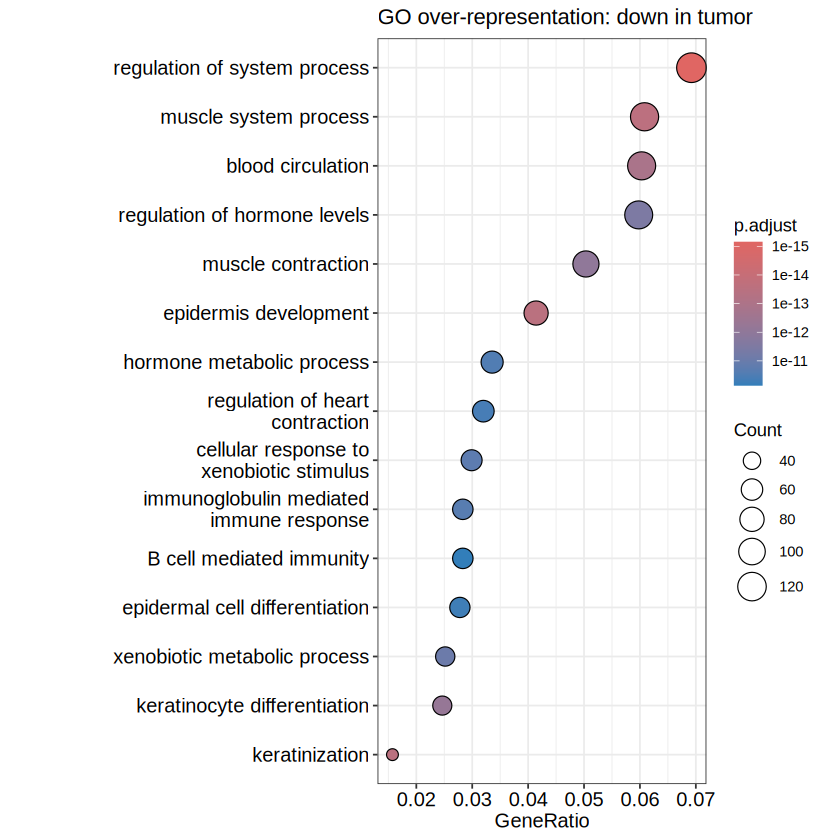

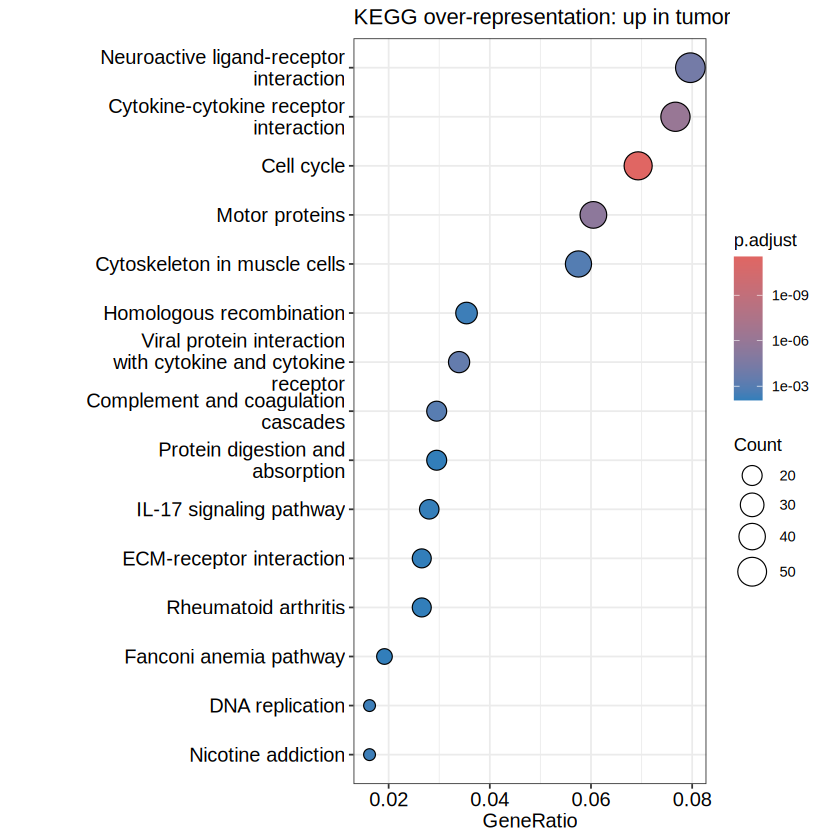

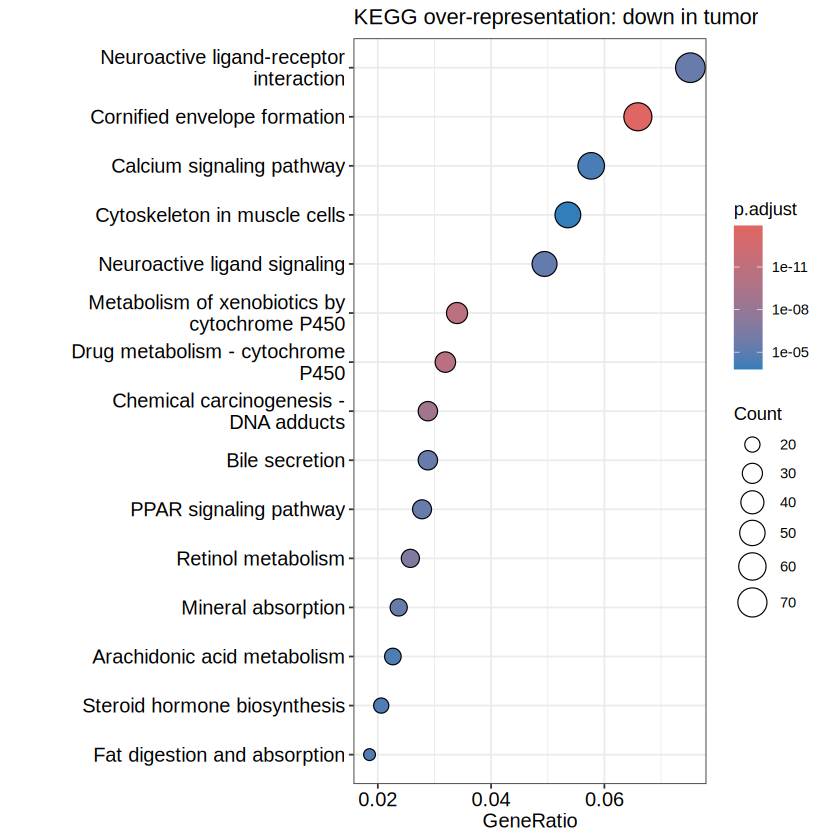

In [17]:
# ORA asks a different question from GSEA: are DEGs over-represented in a term,
# relative to all genes that were tested?
# Up- and down-regulated genes are tested separately. Pooling them loses direction:
# a pooled "muscle contraction" hit can't tell you whether it's higher in tumor or normal.
# The universe is restricted to tested genes with an Entrez ID; using the whole
# genome as background would inflate significance.
up_genes   <- res_df %>% filter(padj < 0.05, lfc_shrunk >  1, !is.na(entrez)) %>% pull(entrez) %>% unique()
down_genes <- res_df %>% filter(padj < 0.05, lfc_shrunk < -1, !is.na(entrez)) %>% pull(entrez) %>% unique()
universe   <- unique(gl_df$entrez)
length(up_genes); length(down_genes)

ora_go_up     <- enrichGO(up_genes,   universe = universe, OrgDb = org.Hs.eg.db, ont = "BP",
                          pvalueCutoff = 0.05, readable = TRUE)
ora_go_down   <- enrichGO(down_genes, universe = universe, OrgDb = org.Hs.eg.db, ont = "BP",
                          pvalueCutoff = 0.05, readable = TRUE)
ora_kegg_up   <- enrichKEGG(up_genes,   universe = universe, organism = "hsa", pvalueCutoff = 0.05)
ora_kegg_down <- enrichKEGG(down_genes, universe = universe, organism = "hsa", pvalueCutoff = 0.05)

# Returns NULL instead of an error when a test has no significant terms.
plot_ora <- function(x, title) {
  if (is.null(x) || nrow(as.data.frame(x)) == 0) { message("No significant terms: ", title); return(NULL) }
  dotplot(x, showCategory = 15) + ggtitle(title) + font_fix
}

ora_plots <- list(
  "06a_ora_go_up"     = plot_ora(ora_go_up,     "GO over-representation: up in tumor"),
  "06b_ora_go_down"   = plot_ora(ora_go_down,   "GO over-representation: down in tumor"),
  "07a_ora_kegg_up"   = plot_ora(ora_kegg_up,   "KEGG over-representation: up in tumor"),
  "07b_ora_kegg_down" = plot_ora(ora_kegg_down, "KEGG over-representation: down in tumor")
)

for (nm in names(ora_plots)) {
  if (!is.null(ora_plots[[nm]])) {
    print(ora_plots[[nm]])
    save_plot(ora_plots[[nm]], sprintf("figures/%s.png", nm), 9, 7)
  }
}

## **8. Sample composition check**

[1] "tissue_or_organ_of_origin"   "site_of_resection_or_biopsy"
[3] "tumor_of_origin"


== tissue_or_organ_of_origin ==
                   
                    Primary Tumor Solid Tissue Normal
  Body of stomach              10                  11
  Cardia, NOS                  13                  13
  Fundus of stomach             8                   0
  Gastric antrum               22                   8
  Liver                         2                   1
  Lymph node, NOS               1                   1
  Not Reported                  2                   2
  Prostate gland                1                   0
  Stomach, NOS                  1                   0

== site_of_resection_or_biopsy ==
              
               Primary Tumor Solid Tissue Normal
  Not Reported             6                   4
  Stomach, NOS            54                  32

== tumor_of_origin ==
                        
                         Primary Tumor Solid Tissue Normal
  TCGA-BR-6458_diagnosis             1                   1
  TCGA-BR-6802_diagnosis             0      

$Normal
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  3.742   4.939   5.570   7.889   5.971  19.996 

$Tumor
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  2.263   4.087   4.559   4.995   5.486  12.593 


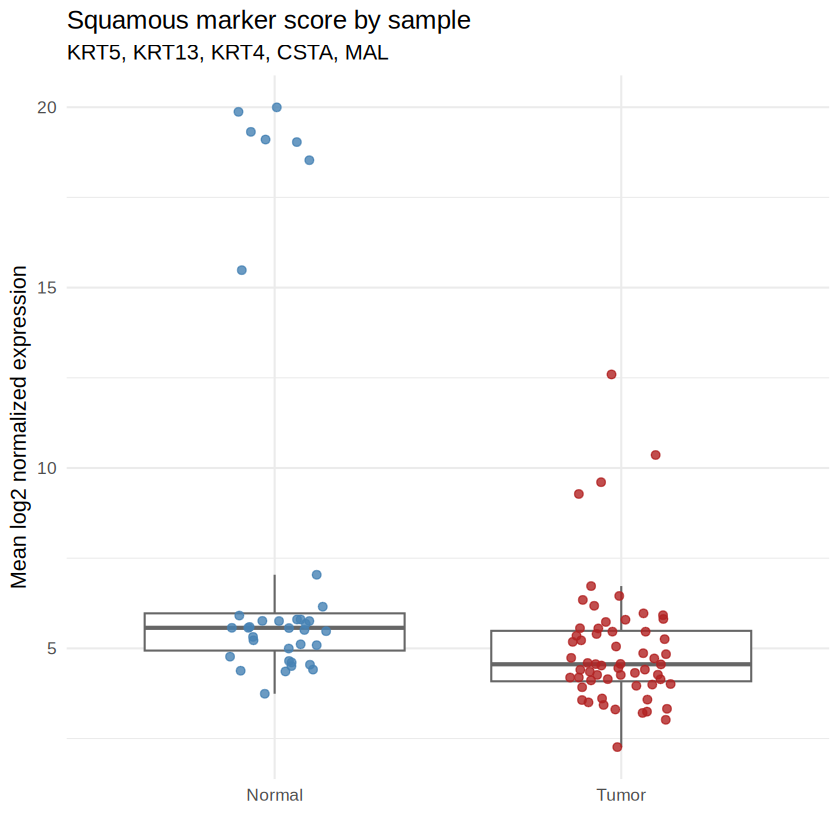

In [18]:
# Keratinization and cornified-envelope terms came out higher in normal samples, and two
# of the top down-regulated genes (CSTA, MAL) are squamous-epithelium markers. Normal
# gastric mucosa doesn't keratinize, so some normals may include esophageal squamous
# tissue taken near the gastroesophageal junction. This cell checks that directly.

# 1) Where were the samples taken? (only simple, non-list columns are tabulated)
site_cols <- grep("site|origin", colnames(colData(stad)), value = TRUE, ignore.case = TRUE)
site_cols <- site_cols[sapply(site_cols, function(x) is.atomic(colData(stad)[[x]]))]
site_cols
for (col in site_cols) {
  cat("\n==", col, "==\n")
  print(table(colData(stad)[[col]], stad$sample_type, useNA = "ifany"))
}

# 2) Squamous marker score per sample: mean log2 normalized expression of
#    canonical esophageal squamous keratins plus CSTA and MAL.
sq_markers <- c("KRT5", "KRT13", "KRT4", "CSTA", "MAL")
sq_ids <- res_df$ensembl_id[match(sq_markers, res_df$symbol)]
sq_ids <- sq_ids[!is.na(sq_ids)]
if (length(sq_ids) == 0) stop("None of the squamous markers passed filtering")

norm_counts <- counts(dds, normalized = TRUE)
sq_df <- data.frame(
  row.names = colnames(dds),
  condition = colData(dds)$condition,
  sq_score  = colMeans(log2(norm_counts[sq_ids, , drop = FALSE] + 1))
)

p_sq <- ggplot(sq_df, aes(condition, sq_score, color = condition)) +
  geom_boxplot(outlier.shape = NA, color = "grey40") +
  geom_jitter(width = 0.15, size = 2, alpha = 0.8) +
  scale_color_manual(values = c("Normal" = "steelblue", "Tumor" = "firebrick")) +
  theme_lab(13) + theme(legend.position = "none") +
  labs(title = "Squamous marker score by sample",
       subtitle = paste(sq_markers[sq_markers %in% res_df$symbol[match(sq_ids, res_df$ensembl_id)]], collapse = ", "),
       x = "", y = "Mean log2 normalized expression")

p_sq
save_plot(p_sq, "figures/08_squamous_marker_score.png", 6, 5)

# A spread-out Normal group, with a subset of high-scoring samples, points to mixed tissue
# rather than a uniform tumor-vs-normal difference.
tapply(sq_df$sq_score, sq_df$condition, summary)

using ntop=500 top features by variance



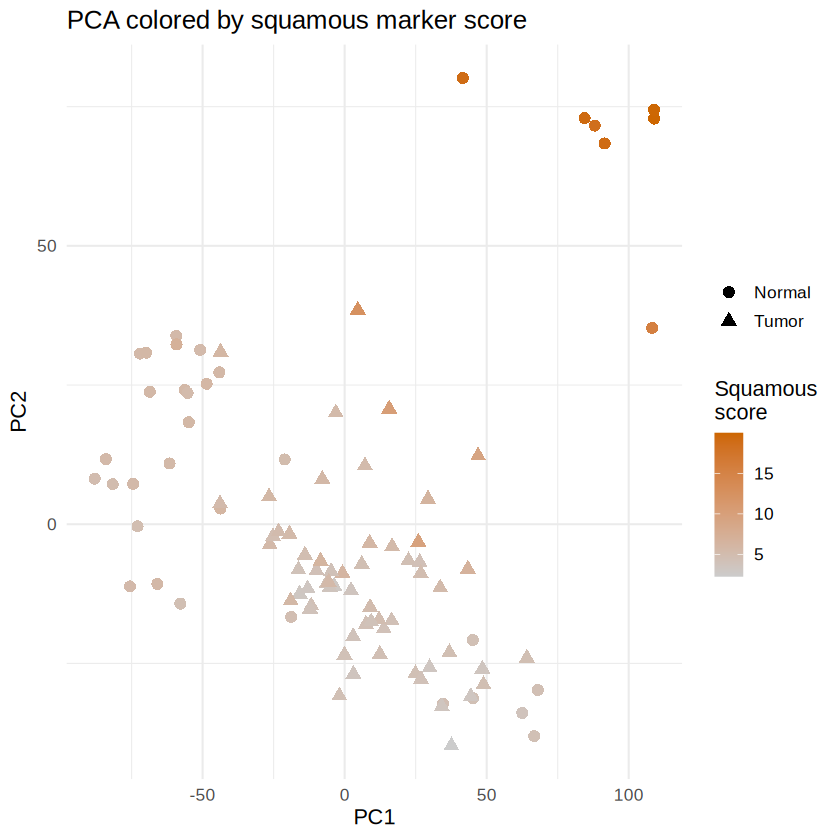

In [19]:
# Overlay the squamous score on the PCA from Section 5. If the separate group of
# normals on PC2 is the squamous-high group, PC2 reflects tissue composition.
pca_df <- plotPCA(vsd, intgroup = "condition", returnData = TRUE)
pca_df$sq_score <- sq_df$sq_score[match(pca_df$name, rownames(sq_df))]

p_pca_sq <- ggplot(pca_df, aes(PC1, PC2, color = sq_score, shape = condition)) +
  geom_point(size = 3) +
  scale_color_gradient(low = "grey80", high = "darkorange3") +
  theme_lab(13) +
  labs(title = "PCA colored by squamous marker score",
       color = "Squamous\nscore", shape = "")
p_pca_sq
save_plot(p_pca_sq, "figures/09b_pca_squamous.png", 7, 6)

## **9. Export**

In [20]:
# Export result tables and bundle with the figures.
# Download results.zip from the Files panel before the runtime ends.
write.csv(res_df, "figures/deseq2_results.csv", row.names = FALSE)
write.csv(as.data.frame(gsea_go),   "figures/gsea_go_results.csv",   row.names = FALSE)
write.csv(as.data.frame(gsea_kegg), "figures/gsea_kegg_results.csv", row.names = FALSE)
write.csv(as.data.frame(ora_go_up),     "figures/ora_go_up.csv",     row.names = FALSE)
write.csv(as.data.frame(ora_go_down),   "figures/ora_go_down.csv",   row.names = FALSE)
write.csv(as.data.frame(ora_kegg_up),   "figures/ora_kegg_up.csv",   row.names = FALSE)
write.csv(as.data.frame(ora_kegg_down), "figures/ora_kegg_down.csv", row.names = FALSE)
write.csv(sq_df, "figures/squamous_marker_score.csv")
write.csv(pos_ctrl, "figures/positive_controls.csv", row.names = FALSE)

zip("results.zip", "figures")

sessionInfo()   # package versions, for reproducibility

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] tibble_3.3.1                dplyr_1.2.1                
 [3] ggrepel_0.9.8               ggplot2_4.0.3              
 [5] enrichplot_1.32.1           org.Hs.eg.

## **10. Interpretation**


### Summary
Differential expression analysis of 60 primary gastric adenocarcinomas and 36 solid tissue normal samples from TCGA-STAD identified 6,855 differentially expressed genes (DEGs; Benjamini-Hochberg adjusted p < 0.05, |log2 fold change| > 1). Relative to normal gastric tissue, tumors showed coordinated up-regulation of DNA replication, cell cycle and DNA repair programs and of extracellular matrix genes, and coordinated down-regulation of mitochondrial oxidative metabolism, fatty acid beta-oxidation and xenobiotic metabolism.

### Quality control
Sample-level and model diagnostics supported the reliability of the differential expression results. Principal component analysis (PCA) of variance-stabilized counts separated tumor and normal samples along PC1 (37% of variance; Fig. 09). The raw p-value distribution showed the expected enrichment near zero over a uniform background (Fig. 10), and the MA and dispersion-estimate plots were consistent with expected model behavior (Figs. 11-12). Seven genes with a known expected direction served as positive controls. The proliferation markers MKI67 and TOP2A were up-regulated in tumors, and the gastric mucosal genes GKN1, GKN2, ATP4A and ATP4B were down-regulated (adjusted p < 0.001 for all six). PGC changed in the expected direction but did not reach significance (adjusted p = 0.11).

### Differentially expressed genes
COL10A1 was the most significant DEG (shrunken log2FC ≈ 7.3), with approximately 100-fold higher median normalized expression in tumors (Figs. 01, 13). Other highly ranked up-regulated genes included COL11A1, CTHRC1 and MMP11, consistent with extensive extracellular matrix remodeling in the tumor stroma.

### Gene set enrichment analysis
Pre-ranked GSEA using the DESeq2 Wald statistic identified 1,251 GO Biological Process terms and 153 KEGG pathways at adjusted p < 0.05 (Figs. 02-05).

Positively enriched gene sets (NES > 0) were dominated by DNA replication, replication fork processing, cell cycle checkpoint signaling, homologous recombination and interstrand cross-link repair, with corresponding KEGG pathways including Cell cycle, Homologous recombination, the Fanconi anemia pathway and Ribosome biogenesis in eukaryotes. The leading edge of DNA-templated DNA replication comprised core replisome, origin-firing and fork-protection components, including RFC3, RFC4, PRIM2, MCM10, CDC7, DBF4 and TIMELESS. Over-representation analysis of up-regulated DEGs independently recovered mitotic processes, including organelle fission, nuclear division and chromosome segregation (Fig. 06a). Together, these results indicate a highly proliferative tumor state with elevated DNA replication and repair activity.

Negatively enriched gene sets (NES < 0) were dominated by mitochondrial respiration (oxidative phosphorylation, respiratory electron transport chain, ATP synthesis coupled electron transport), fatty acid oxidation, and cytochrome P450-mediated xenobiotic and drug metabolism, indicating coordinated lower expression of these programs in tumors relative to normal tissue. The leading edge of fatty acid catabolic process included ACOX1, ECHS1, ETFA, PPARA and PPARD. Over-representation analysis of down-regulated DEGs identified muscle contraction, blood circulation and regulation of hormone levels (Fig. 06b), likely reflecting the smooth muscle, vascular and endocrine components of the normal gastric wall that are underrepresented in tumor samples.

Several KEGG terms require cautious interpretation. The Chemical carcinogenesis pathways consist largely of phase I and phase II detoxification enzymes, and disease-annotated pathways (Parkinson disease, Thermogenesis, Non-alcoholic fatty liver disease) share mitochondrial respiratory-chain genes with oxidative phosphorylation. Their enrichment therefore reflects the same underlying signals rather than disease-specific biology.

### Comparison with Jiang et al. (2023), Figure 7
Jiang et al. compared DLRS-low with DLRS-high tumors, whereas the present analysis compares tumor with normal tissue, so the two analyses address different biological contrasts. Consistent with their findings, DNA repair, which was enriched in DLRS-low tumors (Fig. 7A), and DNA replication and mismatch repair, which appeared among their KEGG results (Fig. 7B), were among the most strongly up-regulated programs in tumors here. In contrast, oxidative phosphorylation and fatty acid metabolism, which were enriched in DLRS-low tumors, were down-regulated in tumors relative to normal tissue. This divergence is expected: tumor-normal comparisons are dominated by differences in tissue composition and differentiation, whereas the DLRS contrast captures heterogeneity among tumors. Likewise, the immune-suppressive signatures associated with DLRS-low tumors reflect intertumoral variation in the tumor microenvironment and would not be expected to emerge from this comparison.

### Sample composition
PCA revealed heterogeneity among normal samples. Approximately 7 of 36 normal samples formed a distinct cluster on PC2 and showed high expression of squamous epithelial markers (KRT5, KRT13, KRT4, CSTA and MAL; Figs. 08, 09b). Because gastric mucosa is a non-keratinizing glandular epithelium, these samples likely contain esophageal squamous mucosa obtained near the gastroesophageal junction, and they account for the keratinization and cornified envelope formation terms among the negatively enriched gene sets.

A subset of tumors showed intermediate squamous scores, consistent with tumors located at or near the junction. A small number of normal samples clustered with tumors, which may reflect tumor-adjacent tissue alterations or tumor cell contamination.

### Limitations
The tumor-normal contrast was used as a surrogate for the DLRS comparison and captures broad differences between malignant and non-malignant tissue rather than the immune-infiltration axis reflected by DLRS.

Analyses were performed on a random subset of 60 of 412 primary tumors (seed = 42) without adjustment for technical covariates such as tissue source site. Because bulk RNA-seq profiles reflect cell-type composition, part of the observed differences likely arises from differences in stromal, immune and epithelial content rather than from tumor cell-intrinsic changes.

The squamous subgroup of normal samples contributes to a subset of negatively enriched terms. Finally, over-representation analysis on approximately 6,800 DEGs favors broad terms; GSEA results were therefore treated as the primary pathway evidence.

### Future directions
(1) Repeat the analysis excluding squamous-high normal samples to assess the robustness of the main findings; (2) analyze the full tumor cohort with tissue source site as a covariate; (3) test MSigDB Hallmark gene sets for direct comparison with Figure 7A; and (4) stratify tumors by an immune-infiltration score (e.g., CD8A, GZMA and PRF1 expression) to approximate the biological axis captured by DLRS.